# ¿Chollo o timo? Detector de pisos mal tasados en Valencia · 02. Modelo de precio justo

**Objetivo:** entrenar un modelo que estime cuánto debería costar cada piso según sus características y su ubicación. Después compararemos ese precio estimado con el precio anunciado para detectar anuncios desviados.

**Cargar los datos limpios**

Leemos desde Google Drive el CSV que guardamos en el notebook anterior.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

import numpy as np
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/detector-pisos/valencia_limpio.csv")
print(df.shape)

Mounted at /content/drive
(27365, 43)


In [3]:
df.columns

Index(['ASSETID', 'PERIOD', 'PRICE', 'UNITPRICE', 'CONSTRUCTEDAREA',
       'ROOMNUMBER', 'BATHNUMBER', 'HASTERRACE', 'HASLIFT',
       'HASAIRCONDITIONING', 'AMENITYID', 'HASPARKINGSPACE',
       'ISPARKINGSPACEINCLUDEDINPRICE', 'PARKINGSPACEPRICE',
       'HASNORTHORIENTATION', 'HASSOUTHORIENTATION', 'HASEASTORIENTATION',
       'HASWESTORIENTATION', 'HASBOXROOM', 'HASWARDROBE', 'HASSWIMMINGPOOL',
       'HASDOORMAN', 'HASGARDEN', 'ISDUPLEX', 'ISSTUDIO', 'ISINTOPFLOOR',
       'CONSTRUCTIONYEAR', 'FLOORCLEAN', 'FLATLOCATIONID',
       'CADCONSTRUCTIONYEAR', 'CADMAXBUILDINGFLOOR', 'CADDWELLINGCOUNT',
       'CADASTRALQUALITYID', 'BUILTTYPEID_1', 'BUILTTYPEID_2', 'BUILTTYPEID_3',
       'DISTANCE_TO_CITY_CENTER', 'DISTANCE_TO_METRO', 'DISTANCE_TO_BLASCO',
       'LONGITUDE', 'LATITUDE', 'BARRIO', 'ESTADO'],
      dtype='object')

**Variables del modelo**

Elegimos qué información usará el modelo: tamaño, extras, estado, antigüedad del edificio, ubicación y barrio.
No incluimos PRICE ni UNITPRICE, porque son lo que queremos predecir.
El objetivo es el logaritmo del precio, para que los errores sean relativos.

In [4]:
df["ANTIGUEDAD"] = 2018 - df["CADCONSTRUCTIONYEAR"]

variables = [
    # tamaño
    "CONSTRUCTEDAREA", "ROOMNUMBER", "BATHNUMBER",
    # extras
    "HASTERRACE", "HASLIFT", "HASAIRCONDITIONING", "HASPARKINGSPACE",
    "HASSWIMMINGPOOL", "HASDOORMAN", "HASGARDEN", "HASBOXROOM",
    "HASWARDROBE", "ISDUPLEX", "ISSTUDIO", "ISINTOPFLOOR",
    "HASNORTHORIENTATION", "HASSOUTHORIENTATION", "HASEASTORIENTATION", "HASWESTORIENTATION",
    "AMENITYID",
    # edificio y estado
    "ANTIGUEDAD", "FLOORCLEAN", "CADMAXBUILDINGFLOOR", "CADDWELLINGCOUNT",
    "CADASTRALQUALITYID", "ESTADO",
    # ubicación
    "LATITUDE", "LONGITUDE", "DISTANCE_TO_CITY_CENTER", "DISTANCE_TO_METRO",
    "DISTANCE_TO_BLASCO", "BARRIO",
]

X = df[variables].copy()
X["ESTADO"] = X["ESTADO"].astype("category")
X["BARRIO"] = X["BARRIO"].astype("category")

y = np.log(df["PRICE"])

print("Variables:", X.shape[1])
print("Pisos:", len(X))

Variables: 32
Pisos: 27365


# ENTRENAMIENTO

**Separar entrenamiento y prueba sin hacer trampa:**

Si separamos los pisos al azar, pisos del mismo edificio (o el mismo piso anunciado por dos inmobiliarias) podrían acabar uno en entrenamiento y otro en prueba. El modelo “reconocería” el piso y parecería más preciso de lo que es.
Para evitarlo, dividimos la ciudad en una cuadrícula de unos 500 m y mandamos cada cuadrado entero a entrenamiento o a prueba.

In [6]:
from sklearn.model_selection import GroupShuffleSplit

# Cuadrícula de ~500 m: redondeamos las coordenadas
cuadro = (df["LATITUDE"] / 0.0045).round().astype(int).astype(str) + "_" + \
         (df["LONGITUDE"] / 0.0058).round().astype(int).astype(str)

separador = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
idx_train, idx_test = next(separador.split(X, y, groups=cuadro))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]

print("Entrenamiento:", len(X_train), "pisos")
print("Test:", len(X_test), "pisos")
print("Cuadrados de la cuadrícula:", cuadro.nunique())

Entrenamiento: 21686 pisos
Test: 5679 pisos
Cuadrados de la cuadrícula: 183


**Resultado:** 21.686 pisos para entrenar y 5.679 para test (79% / 21%), repartidos en 183 cuadrados de unos 500 m.

**Modelo de referencia (baseline)**

Antes de usar Machine Learning, necesitamos una referencia sencilla con la que compararnos: precio = metros del piso × €/m² mediano de su barrio.
Si el modelo no mejora claramente esta regla, no merece la pena usarlo.
La mediana de cada barrio se calcula solo con los pisos de entrenamiento, para no usar información de los de prueba.

In [7]:
train = df.iloc[idx_train]
test = df.iloc[idx_test]

eur_m2_barrio = train.groupby("BARRIO")["UNITPRICE"].median()
eur_m2_ciudad = train["UNITPRICE"].median()

eur_m2_test = test["BARRIO"].map(eur_m2_barrio).fillna(eur_m2_ciudad)
pred_baseline = test["CONSTRUCTEDAREA"] * eur_m2_test

precio_real = test["PRICE"]
error_baseline = np.abs(pred_baseline - precio_real) / precio_real * 100

print(f"Error mediano del baseline: {error_baseline.median():.1f}%")

Error mediano del baseline: 19.3%


**Modelo LightGBM**

LightGBM es un modelo de árboles de decisión potenciados (gradient boosting). Lo elegimos porque:

capta relaciones no lineales, como la de la antigüedad, que vimos en la exploración;
acepta directamente variables categóricas como el barrio;
gestiona los valores nulos sin tener que rellenarlos.

In [8]:
import lightgbm as lgb

modelo = lgb.LGBMRegressor(
    n_estimators=1000,
    learning_rate=0.03,
    num_leaves=31,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    random_state=42,
    verbose=-1,
)
modelo.fit(X_train, y_train)

pred_modelo = np.exp(modelo.predict(X_test))
error_modelo = np.abs(pred_modelo - precio_real) / precio_real * 100

print(f"Error mediano de LightGBM: {error_modelo.median():.1f}%")

Error mediano de LightGBM: 13.5%


**Comparación**

Medimos el error porcentual mediano: cuánto se equivoca el modelo, en %, en un piso típico. Es la métrica habitual en tasación inmobiliaria porque se entiende fácilmente.

In [9]:
pd.DataFrame({
    "error mediano (%)": [error_baseline.median(), error_modelo.median()],
    "pisos con error < 10% (%)": [(error_baseline < 10).mean() * 100,
                                  (error_modelo < 10).mean() * 100],
}, index=["Baseline (m² × barrio)", "LightGBM"]).round(1)

,error mediano (%),pisos con error < 10% (%)
Baseline (m² × barrio),19.3,27.9
LightGBM,13.5,38.9


LightGBM reduce el error mediano del 19,3% al 13,5% frente al baseline, y el porcentaje de pisos con un error menor del 10% sube del 27,9% al 38,9%.
Parte del error que queda es la señal que buscamos: anuncios cuyo precio se aleja de lo que dicen sus características.

**Precio justo de todos los pisos**

Dividimos los pisos en 5 grupos (respetando los cuadrados de 500 m). Para cada grupo entrenamos el modelo con los otros 4 y predecimos ese grupo. Así cada piso recibe un precio justo calculado por un modelo que nunca lo ha visto (predicción out-of-fold).
La desviación indica cuánto más caro (+) o más barato (−) se anuncia el piso respecto a su precio justo.

In [10]:
from sklearn.model_selection import GroupKFold, cross_val_predict

pred_log = cross_val_predict(modelo, X, y, groups=cuadro, cv=GroupKFold(n_splits=5))

df["PRECIO_JUSTO"] = np.exp(pred_log).round(-3)
df["DESVIACION_%"] = ((df["PRICE"] / df["PRECIO_JUSTO"] - 1) * 100).round(1)

df[["BARRIO", "CONSTRUCTEDAREA", "PRICE", "PRECIO_JUSTO", "DESVIACION_%"]].head(10)

,BARRIO,CONSTRUCTEDAREA,PRICE,PRECIO_JUSTO,DESVIACION_%
0,NaN,62,30000.0,45000.0,-33.3
1,L'Hort de Senabre,88,104000.0,97000.0,7.2
2,El Botànic,150,333000.0,382000.0,-12.8
3,La Raiosa,120,155000.0,166000.0,-6.6
4,La Raiosa,88,93000.0,131000.0,-29.0
5,El Pla del Remei,203,680000.0,673000.0,1.0
6,Arrancapins,114,247000.0,216000.0,14.4
7,Mont-Olivet,127,214000.0,164000.0,30.5
8,Mont-Olivet,127,208000.0,186000.0,11.8
9,Ciutat de les Arts i de les Ciencies,169,850000.0,395000.0,115.2


**Marcar los anuncios sospechosos**

Marcamos como “caro” un piso anunciado por más de 1,5 veces su precio justo (+50%) y como “barato” uno anunciado por menos de 2/3 de su precio justo (−33%).
Los umbrales son simétricos en escala logarítmica: pasarse por arriba o por abajo en la misma proporción cuenta igual.

In [11]:
ratio = df["PRICE"] / df["PRECIO_JUSTO"]

df["ALERTA"] = "normal"
df.loc[ratio > 1.5, "ALERTA"] = "caro"
df.loc[ratio < 1 / 1.5, "ALERTA"] = "barato"

df["ALERTA"].value_counts()

,count
ALERTA,
normal,25292
caro,1115
barato,958


**¿Mejora al detector ingenuo?**

Repetimos la prueba del notebook anterior: si el modelo funciona, los pisos marcados ya no deberían ser casi todos de obra nueva (“caros”) o a reformar (“baratos”), porque el modelo ya tiene en cuenta el estado del piso.

In [12]:
pd.crosstab(df["ALERTA"], df["ESTADO"], normalize="index").mul(100).round(1)

ESTADO,a reformar,buen estado,obra nueva
ALERTA,,,
barato,15.6,82.5,2.0
caro,10.9,86.5,2.6
normal,12.9,83.8,3.3


Con el modelo, los pisos marcados tienen una mezcla de estados casi igual a la del resto: solo el 15,6% de los “baratos” están a reformar (frente al 30% con el detector ingenuo) y solo el 2,6% de los “caros” son obra nueva (frente al 12%).
El modelo ya descuenta el estado del piso, así que las alertas responden al precio y no a características que lo justifican.

**Los casos más llamativos**

Vemos los 10 anuncios más caros y los 10 más baratos respecto a su precio justo. Son los que revisaría primero un comprador, una inmobiliaria o un portal que quiera detectar errores o fraudes.

In [16]:
columnas = ["BARRIO", "CONSTRUCTEDAREA", "ROOMNUMBER", "ESTADO",
            "PRICE", "UNITPRICE", "PRECIO_JUSTO", "DESVIACION_%"]

print("Anunciados muy por ENCIMA de su precio justo:")
display(df.sort_values("DESVIACION_%", ascending=False)[columnas].head(10))

print("Anunciados muy por DEBAJO de su precio justo:")
display(df.sort_values("DESVIACION_%")[columnas].head(10))

Anunciados muy por ENCIMA de su precio justo:


,BARRIO,CONSTRUCTEDAREA,ROOMNUMBER,ESTADO,PRICE,UNITPRICE,PRECIO_JUSTO,DESVIACION_%
25727,L'Hort de Senabre,45,0,buen estado,322000.0,7155.555556,43000.0,648.8
19371,Ciutat Jardí,139,4,a reformar,1031000.0,7417.266187,169000.0,510.1
21515,Patraix,60,1,buen estado,555000.0,9250.000000,95000.0,484.2
21390,Patraix,150,4,buen estado,1175000.0,7833.333333,216000.0,444.0
10761,Tres Forques,55,1,buen estado,264000.0,4800.000000,49000.0,438.8
2530,Torrefiel,82,3,buen estado,395000.0,4817.073171,74000.0,433.8
4635,Tormos,94,3,buen estado,479000.0,5095.744681,94000.0,409.6
1255,Patraix,106,3,buen estado,553000.0,5216.981132,117000.0,372.6
26713,El Grau,137,4,buen estado,964000.0,7036.496350,208000.0,363.5
17095,Tres Forques,50,2,buen estado,209000.0,4180.000000,46000.0,354.3


Anunciados muy por DEBAJO de su precio justo:


,BARRIO,CONSTRUCTEDAREA,ROOMNUMBER,ESTADO,PRICE,UNITPRICE,PRECIO_JUSTO,DESVIACION_%
9264,Sant Francesc,99,4,a reformar,57000.0,575.757576,270000.0,-78.9
26015,Sant Francesc,111,2,buen estado,69000.0,621.621622,292000.0,-76.4
24845,El Pla del Remei,75,3,buen estado,40000.0,533.333333,157000.0,-74.5
12992,Sant Francesc,118,2,buen estado,97000.0,822.033898,381000.0,-74.5
7269,El Pla del Remei,124,4,buen estado,113000.0,911.290323,407000.0,-72.2
18578,Penya-Roja,131,2,buen estado,128000.0,977.099237,449000.0,-71.5
5628,Russafa,67,2,buen estado,35000.0,522.388060,122000.0,-71.3
13889,Penya-Roja,79,4,buen estado,64000.0,810.126582,221000.0,-71.0
8008,L'Illa Perduda,41,0,a reformar,20000.0,487.804878,69000.0,-71.0
4922,Mestalla,110,3,buen estado,73000.0,663.636364,248000.0,-70.6


**Patrón:** los anuncios más “caros” están en barrios baratos, con precios por m² propios del centro; los más “baratos” están en los barrios más caros, a precios por m² imposibles para la zona.
Los casos extremos no parecen chollos ni sobreprecios, sino anuncios anómalos: probables errores de carga (metros, tipo de inmueble o ubicación) o ventas especiales que el dataset no distingue (nuda propiedad, viviendas ocupadas, subastas o ventas parciales).
El detector es útil como herramienta de revisión: prioriza qué anuncios debería comprobar una persona. Los casos con desviaciones moderadas (+50% a +150%, o −33% a −60%) son los candidatos más realistas a pisos de verdad mal tasados.

**¿Qué variables pesan más en el precio? (SHAP)**

Usamos valores SHAP, que reparten la predicción de cada piso entre sus variables: cuánto suma o resta cada una al precio. LightGBM los calcula directamente con pred_contrib=True, sin instalar nada.
Como el modelo trabaja en logaritmo, el impacto se puede leer aproximadamente como porcentaje del precio.

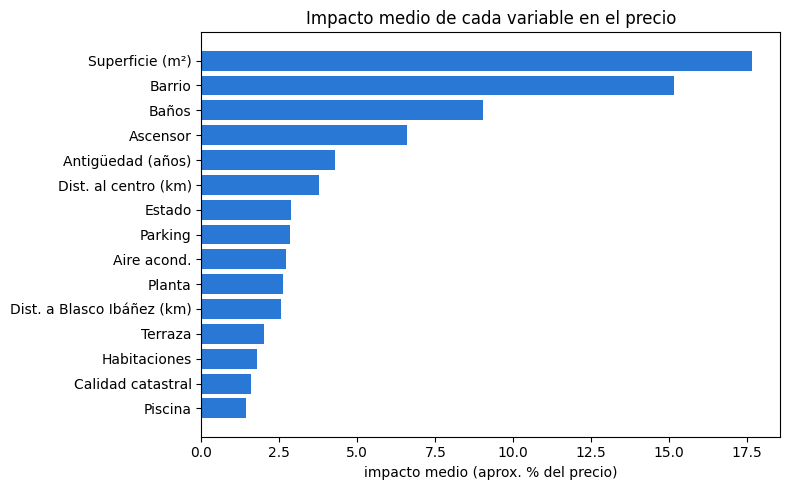

In [21]:
import matplotlib.pyplot as plt

nombres = {
    "CONSTRUCTEDAREA": "Superficie (m²)", "ROOMNUMBER": "Habitaciones", "BATHNUMBER": "Baños",
    "HASTERRACE": "Terraza", "HASLIFT": "Ascensor", "HASAIRCONDITIONING": "Aire acond.",
    "HASPARKINGSPACE": "Parking", "HASSWIMMINGPOOL": "Piscina", "HASDOORMAN": "Portero",
    "HASGARDEN": "Jardín", "ISINTOPFLOOR": "Ático", "ANTIGUEDAD": "Antigüedad (años)",
    "FLOORCLEAN": "Planta", "CADASTRALQUALITYID": "Calidad catastral", "ESTADO": "Estado",
    "BARRIO": "Barrio", "LATITUDE": "Latitud", "LONGITUDE": "Longitud",
    "DISTANCE_TO_CITY_CENTER": "Dist. al centro (km)", "DISTANCE_TO_METRO": "Dist. al metro (km)",
    "DISTANCE_TO_BLASCO": "Dist. a Blasco Ibáñez (km)", "CADMAXBUILDINGFLOOR": "Plantas del edificio",
    "CADDWELLINGCOUNT": "Viviendas del edificio",
}

contrib = modelo.predict(X_test, pred_contrib=True)   # la última columna es el valor base
impacto = pd.Series(np.abs(contrib[:, :-1]).mean(axis=0) * 100, index=X.columns)
impacto = impacto.sort_values().tail(15)

plt.figure(figsize=(8, 5))
plt.barh(impacto.index.map(lambda v: nombres.get(v, v)), impacto.values, color="#2a78d6")
plt.title("Impacto medio de cada variable en el precio")
plt.xlabel("impacto medio (aprox. % del precio)")
plt.tight_layout()
plt.savefig("shap_global.png", dpi=150, bbox_inches="tight")
plt.show()

Las variables que más pesan son la superficie (~17%) y el barrio (~15%), seguidas del número de baños (~9%) y el ascensor (~6,5%).

Los baños pesan mucho más que las habitaciones: una vez conocidos los metros, una habitación más no añade casi nada, mientras que un baño extra indica un piso de más categoría.
El portero y la piscina, que en la exploración parecían los extras más valiosos, apenas influyen en el modelo. Su efecto aparente se debía a que suelen estar en pisos grandes y en buenos barrios: era correlación, no efecto propio. El modelo separa ambos efectos y la comparación descriptiva no.

Barrio: Na Rovella · 68 m² · 2 hab. · buen estado
Precio base de la ciudad: 155,960 €
Precio justo según el modelo: 80,886 €
Precio anunciado: 120,000 € (+48% sobre su precio justo)


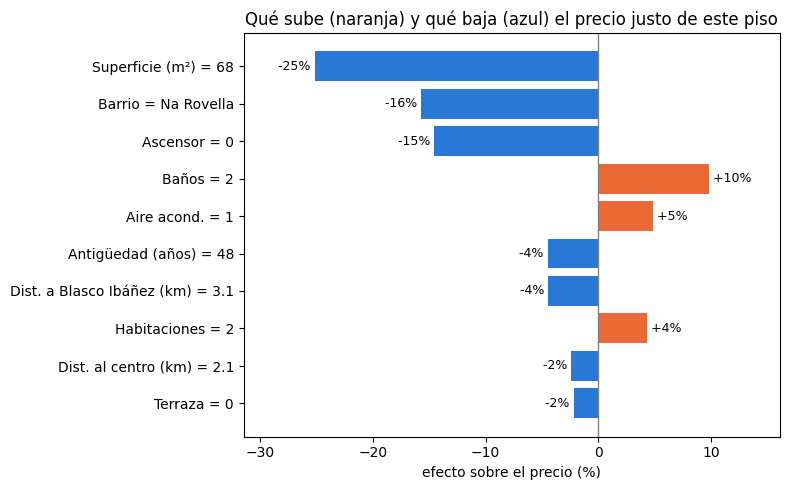

In [22]:
# Un piso de prueba marcado como caro, con una desviación moderada
candidatos = df.iloc[idx_test]
candidatos = candidatos[candidatos["DESVIACION_%"].between(50, 150)]
fila = candidatos.index[0]          # cambia el 0 por otro número para ver otro piso
piso = df.loc[fila]

# Contribuciones SHAP de cada variable para este piso
contrib = modelo.predict(X.loc[[fila]], pred_contrib=True)[0]
precio_base = np.exp(contrib[-1])
precio_modelo = np.exp(contrib.sum())
efectos = pd.Series((np.exp(contrib[:-1]) - 1) * 100, index=X.columns)

print(f"Barrio: {piso['BARRIO']} · {piso['CONSTRUCTEDAREA']:.0f} m² · "
      f"{piso['ROOMNUMBER']:.0f} hab. · {piso['ESTADO']}")
print(f"Precio base de la ciudad: {precio_base:,.0f} €")
print(f"Precio justo según el modelo: {precio_modelo:,.0f} €")
print(f"Precio anunciado: {piso['PRICE']:,.0f} € "
      f"({(piso['PRICE'] / precio_modelo - 1) * 100:+.0f}% sobre su precio justo)")

# Las 10 variables que más mueven el precio de este piso
top = efectos.reindex(efectos.abs().sort_values(ascending=False).index).head(10)[::-1]
colores = ["#eb6834" if e > 0 else "#2a78d6" for e in top]

def formato(valor):
    if isinstance(valor, (float, np.floating)) and valor % 1:
        return round(valor, 1)
    return valor

etiquetas = [f"{nombres.get(v, v)} = {formato(X.loc[fila, v])}" for v in top.index]

plt.figure(figsize=(8, 5))
plt.barh(etiquetas, top.values, color=colores)
plt.axvline(0, color="grey", linewidth=1)
margen = top.abs().max() * 0.25
plt.xlim(min(top.min(), 0) - margen, max(top.max(), 0) + margen)
for i, e in enumerate(top.values):
    plt.text(e, i, f" {e:+.0f}% ", va="center", ha="left" if e > 0 else "right", fontsize=9)
plt.title("Qué sube (naranja) y qué baja (azul) el precio justo de este piso")
plt.xlabel("efecto sobre el precio (%)")
plt.tight_layout()
plt.savefig("shap_piso.png", dpi=150, bbox_inches="tight")
plt.show()

 **Ejemplo:** piso en Na Rovella de 68 m², 2 habitaciones y en buen estado. Partiendo del precio típico de la ciudad (156.000 €), el modelo lo rebaja por su tamaño (−25%), su barrio (−16%) y la falta de ascensor (−15%), y lo sube por tener 2 baños (+10%) y aire acondicionado (+5%). Su precio justo es de unos 81.000 €, pero se anuncia por 120.000 €: un 48% por encima.
Así, cada alerta del detector viene con una explicación comprensible de por qué el precio no encaja.

**Guardar los resultados**

Guardamos en Drive cada piso con su precio justo, su desviación y su alerta, además del modelo entrenado, para reutilizarlos en una futura app o dashboard.

In [19]:
import joblib

carpeta = "/content/drive/MyDrive/detector-pisos"

resultados = df[["ASSETID", "BARRIO", "LATITUDE", "LONGITUDE", "CONSTRUCTEDAREA",
                 "ROOMNUMBER", "BATHNUMBER", "ESTADO", "PRICE", "UNITPRICE",
                 "PRECIO_JUSTO", "DESVIACION_%", "ALERTA"]]
resultados.to_csv(f"{carpeta}/valencia_resultados.csv", index=False)

joblib.dump(modelo, f"{carpeta}/modelo_lightgbm.pkl")

print("Resultados guardados:", resultados.shape)
print(resultados["ALERTA"].value_counts())

Resultados guardados: (27365, 13)
ALERTA
normal    25292
caro       1115
barato      958
Name: count, dtype: int64
